In [2]:
import os
import numpy as np
import mne
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

from scipy.signal import butter, filtfilt
from scipy.stats import circmean

from convnwb.io import open_h5file, get_files, load_config, save_json, load_json,make_session_name
from convnwb.paths import Paths



/Users/weijiazhang/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [3]:
import sys
sys.path.append('../code')
from models import PLACE_MODELS, create_df_place, fit_anova_place
from get_neuraldata import get_spike_indx,get_wave_data
from plt import plot_positions_with_speed
from utils import get_values_by_times,find_place_field,find_place_location
from report import create_f_place_field_str,create_b_place_field_str
sys.path.append('../scripts')
from settings import RUN, PATHS, PLACE,UNITS,METHODS, OCCUPANCY, BINS, SURROGATES,SAMPLING_RATE

# Load LFP data

In [32]:
# --- Set session name and path ---
session = "ec013.156"

sess_path = "/Users/weijiazhang/Data/CRNCS_hc3/linear/recordings/ec013/ec013.15/ec013.156/"  # adjust if your data is nested

eeg_path = os.path.join(sess_path, f"{session}.eeg")
xml_path = os.path.join(sess_path, f"{session}.xml")

# --- Parse XML ---
tree = ET.parse(xml_path)
root = tree.getroot()

n_channels = int(root.find("acquisitionSystem").find("nChannels").text)
sampling_rate = int(root.find("fieldPotentials").find("lfpSamplingRate").text)
# scale = 0.195e-6  # volts per bit (µV)

# --- Load EEG ---
raw_data = np.fromfile(eeg_path, dtype=np.int16)
n_samples = raw_data.size // n_channels
data = raw_data.reshape((n_samples, n_channels)).T
# data = data * scale  # convert to volts



## Load Spike Data

In [38]:
get_files(sess_path)

['ec013.156.clu.1',
 'ec013.156.clu.2',
 'ec013.156.clu.3',
 'ec013.156.clu.4',
 'ec013.156.clu.5',
 'ec013.156.clu.6',
 'ec013.156.clu.7',
 'ec013.156.clu.8',
 'ec013.156.eeg',
 'ec013.156.fet.1',
 'ec013.156.fet.2',
 'ec013.156.fet.3',
 'ec013.156.fet.4',
 'ec013.156.fet.5',
 'ec013.156.fet.6',
 'ec013.156.fet.7',
 'ec013.156.fet.8',
 'ec013.156.m1m2.1',
 'ec013.156.m1m2.2',
 'ec013.156.m1m2.3',
 'ec013.156.m1m2.4',
 'ec013.156.m1m2.5',
 'ec013.156.m1m2.6',
 'ec013.156.m1m2.7',
 'ec013.156.m1m2.8',
 'ec013.156.nrs',
 'ec013.156.res.1',
 'ec013.156.res.2',
 'ec013.156.res.3',
 'ec013.156.res.4',
 'ec013.156.res.5',
 'ec013.156.res.6',
 'ec013.156.res.7',
 'ec013.156.res.8',
 'ec013.156.spk.1',
 'ec013.156.spk.2',
 'ec013.156.spk.3',
 'ec013.156.spk.4',
 'ec013.156.spk.5',
 'ec013.156.spk.6',
 'ec013.156.spk.7',
 'ec013.156.spk.8',
 'ec013.156.threshold.1',
 'ec013.156.threshold.2',
 'ec013.156.threshold.3',
 'ec013.156.threshold.4',
 'ec013.156.threshold.5',
 'ec013.156.threshold.6',


In [39]:
spike_data,n_units= get_spike_indx(sess_path)
n_elec = len(data)
print(' ')
print('Number of electrode: ',n_elec)
print('Total Units: ',n_units)

Elec 0: 21 Clusters
Elec 1: 20 Clusters
Elec 2: 18 Clusters
Elec 3: 16 Clusters
Elec 4: 7 Clusters
Elec 5: 7 Clusters
Elec 6: 7 Clusters
Elec 7: 3 Clusters
 
Number of electrode:  65
Total Units:  99


In [40]:
all_spikes = []
for i in range(len(spike_data)):
    spike_inds = spike_data[str(i)]
    for i,(units, unit_spikes)in enumerate(spike_inds.items()):
        spikes = unit_spikes/SAMPLING_RATE['SPIKE']
        all_spikes.append(spikes)

In [41]:
data.shape

(65, 1279488)

## Preprocess Position Data 

In [42]:
whl = np.loadtxt('/Users/weijiazhang/Data/CRNCS_hc3/linear/recordings/ec013/ec013.15/ec013.156/ec013.156.whl')  # shape: (n_samples, 4)
print(whl.shape)

(39985, 4)


In [43]:
x1 = whl[:, 0].astype(float)
x2 = whl[:, 2].astype(float)
time_idx = np.arange(len(x1))

# Replace -1 with np.nan for consistent missing value handling
x1[x1 == -1] = np.nan
x2[x2 == -1] = np.nan


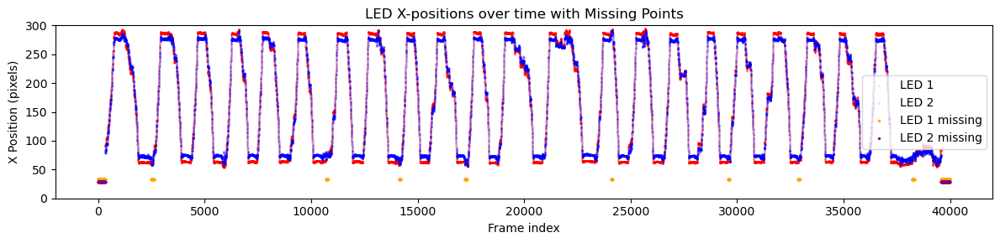

In [44]:

# Plot the data
plt.figure(figsize=(12, 3))
plt.scatter(time_idx[~np.isnan(x1)], x1[~np.isnan(x1)], color='red', alpha=0.1, s=1, label='LED 1')
plt.scatter(time_idx[~np.isnan(x2)], x2[~np.isnan(x2)], color='blue', alpha=0.1, s=1, label='LED 2')

# Overlay missing values as dots at an offset
y_offset = np.nanmin([np.nanmin(x1), np.nanmin(x2)]) - 20
plt.scatter(time_idx[np.isnan(x1)], np.full(np.sum(np.isnan(x1)), y_offset), color='orange', s=2, label='LED 1 missing')
plt.scatter(time_idx[np.isnan(x2)], np.full(np.sum(np.isnan(x2)), y_offset - 5), color='purple', s=2, label='LED 2 missing')

# Format the plot
plt.title("LED X-positions over time with Missing Points")
plt.xlabel("Frame index")
plt.ylim([0, 300])
plt.ylabel("X Position (pixels)")
plt.legend()
plt.tight_layout()
plt.show()


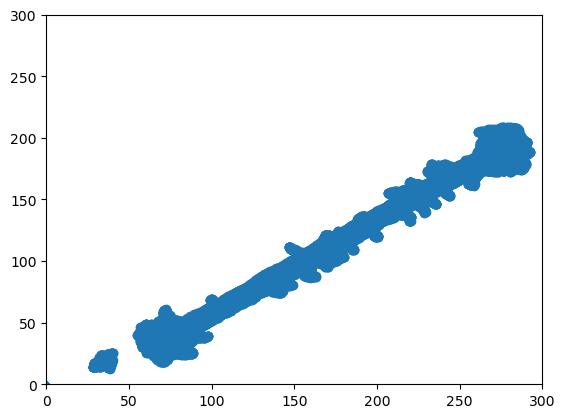

In [45]:
pos_test = 0.5 * (whl[:, 0:2] + whl[:, 2:4])  # average of LED1 and LED2
pos_test.shape
plt.scatter(pos_test[:,0], pos_test[:,1])
plt.xlim(0,300)
plt.ylim(0,300)
plt.show()

# behavioral data preprocessing: position, head direction, velocity, (boundary, grid?,)

In [46]:
fs_pos = 39.0625  # position sampling rate
n_frames = len(whl)
t = np.arange(n_frames) / fs_pos

# Split LED positions and replace -1 with NaN
led1 = whl[:, 0:2].astype(float)
led2 = whl[:, 2:4].astype(float)
led1[led1 == -1] = np.nan
led2[led2 == -1] = np.nan


## interpolation position for nan/-1

In [47]:
def fill_nearest(arr):
    """Fill NaNs using nearest non-NaN values (repetitive fill)."""
    mask = np.isnan(arr)
    if np.all(mask):  # if the entire column is NaN
        return arr
    idx = np.where(~mask, np.arange(len(arr)), 0)
    filled_idx = np.interp(np.arange(len(arr)), np.arange(len(arr))[~mask], arr[~mask])
    return filled_idx

# Apply to each LED and each coordinate (x, y)
interp_led1 = np.apply_along_axis(fill_nearest, 0, led1)
interp_led2 = np.apply_along_axis(fill_nearest, 0, led2)


In [48]:
interp_led1.shape,data.shape

((39985, 2), (65, 1279488))

## position

In [49]:
# Mean position
mean_pos = (interp_led1 + interp_led2) / 2
# Linear position: project mean_pos onto best-fit line (via PCA)
from sklearn.decomposition import PCA
pca_position = PCA(n_components=1)
linear_pos = pca_position.fit_transform(mean_pos).flatten()

## head direction

In [50]:
# # Head direction (radians)
# vec = interp_led2 - interp_led1
# head_dir = np.arctan2(vec[:, 1], vec[:, 0])  # angle of LED2 - LED1 vector

In [51]:
track_vector = pca_position.components_[0]  # shape (2,)
vec = interp_led2 - interp_led1  # original head direction vector
dot = np.sum(vec * track_vector, axis=1)
det = vec[:, 0] * track_vector[1] - vec[:, 1] * track_vector[0]
head_dir_relative = np.arctan2(det, dot)  # in radians
head_dir_deg = np.degrees(head_dir_relative)  # now 0° = forward, ±180° = reverse


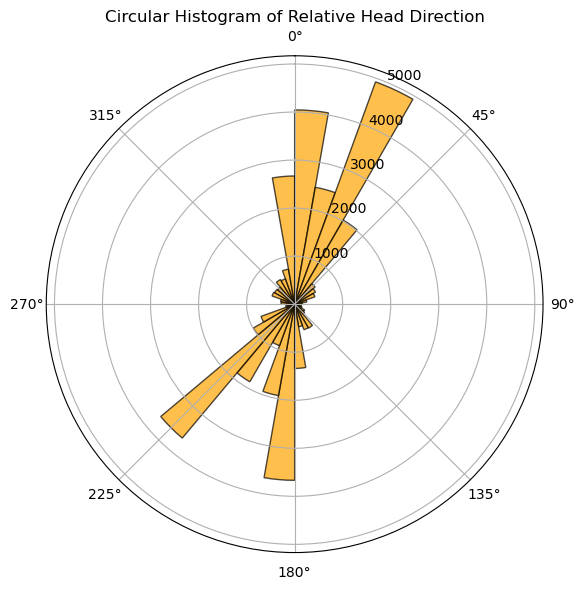

In [52]:
# Plot circular histogram
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, polar=True)

# Histogram parameters
n_bins = 36
counts, bin_edges = np.histogram(head_dir_relative, bins=n_bins, range=(-np.pi, np.pi))
widths = np.diff(bin_edges)
angles = bin_edges[:-1] + widths / 2

# Plot histogram as bars
ax.bar(angles, counts, width=widths, bottom=0.0, color='orange', alpha=0.7, edgecolor='k')

ax.set_theta_zero_location("N")  # 0 at the top
ax.set_theta_direction(-1)       # clockwise
ax.set_title("Circular Histogram of Relative Head Direction")

plt.tight_layout()
plt.show()

## velocity & speed

In [53]:
# Velocity: compute speed from linearized position
dx = np.gradient(linear_pos) # velocity direction
speed = np.abs(dx) * fs_pos  # convert to units/sec


## interpolate as to LFP

In [54]:
n_lfp_samples = data.shape[1]
lfp_time = np.arange(n_lfp_samples) / sampling_rate
pos_time = np.arange(len(linear_pos)) / 39.0625

def interp_signal(signal, kind='linear'):
    mask = ~np.isnan(signal)
    f = interp1d(pos_time[mask], signal[mask], kind=kind, bounds_error=False, fill_value='extrapolate')
    return f(lfp_time)

interp_linear_pos = interp_signal(linear_pos)
interp_speed = interp_signal(speed)
interp_head_dir = interp_signal(head_dir_relative)

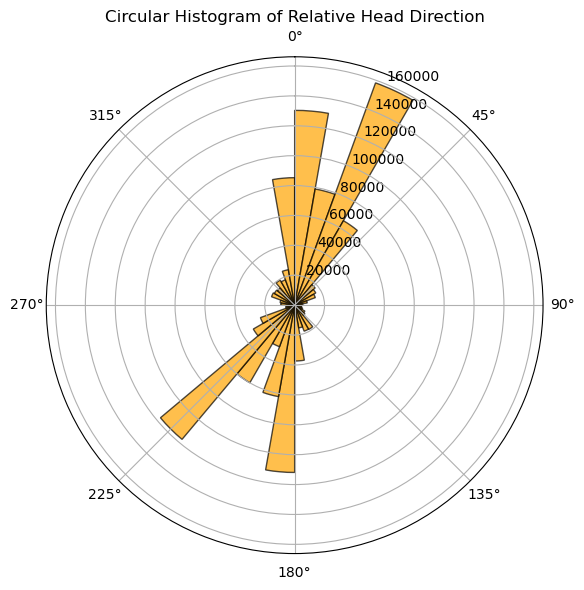

In [55]:
# Plot circular histogram
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, polar=True)

# Histogram parameters
n_bins = 36
counts, bin_edges = np.histogram(interp_head_dir, bins=n_bins, range=(-np.pi, np.pi))
widths = np.diff(bin_edges)
angles = bin_edges[:-1] + widths / 2

# Plot histogram as bars
ax.bar(angles, counts, width=widths, bottom=0.0, color='orange', alpha=0.7, edgecolor='k')

ax.set_theta_zero_location("N")  # 0 at the top
ax.set_theta_direction(-1)       # clockwise
ax.set_title("Circular Histogram of Relative Head Direction")

plt.tight_layout()
plt.show()

# data summary

In [56]:
t_lfp = np.arange(data.shape[1]) / sampling_rate
t_pos = np.arange(len(linear_pos)) / 39.0625

In [57]:
summary_combined = {
    "LFP sampling rate (Hz)": sampling_rate,
    "LFP shape (channels x samples)": data.shape,

    "LFP duration (s)": data.shape[1] / sampling_rate,
    "Original position shape": linear_pos.shape,
    "Original speed shape": speed.shape,
    "Original head direction shape": head_dir_relative.shape,
    "Original position sampling rate (Hz)": fs_pos,
    "Interpolated position shape": interp_linear_pos.shape,
    "Interpolated speed shape": interp_speed.shape,
    "Interpolated head direction shape": interp_head_dir.shape,
    "Interpolated duration (s)": interp_linear_pos.shape[0] / sampling_rate,
    "Interpolated sample count matches LFP": interp_linear_pos.shape[0] == data.shape[1]
}

summary_combined

{'LFP sampling rate (Hz)': 1250,
 'LFP shape (channels x samples)': (65, 1279488),
 'LFP duration (s)': 1023.5904,
 'Original position shape': (39985,),
 'Original speed shape': (39985,),
 'Original head direction shape': (39985,),
 'Original position sampling rate (Hz)': 39.0625,
 'Interpolated position shape': (1279488,),
 'Interpolated speed shape': (1279488,),
 'Interpolated head direction shape': (1279488,),
 'Interpolated duration (s)': 1023.5904,
 'Interpolated sample count matches LFP': True}

## visualization

/var/folders/tx/9bxcz_2j6m79n4dmyyw6s2zm0000gn/T/ipykernel_92355/347061633.py:31: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  ax_polar = plt.subplot(2, 2, 3, polar=True)


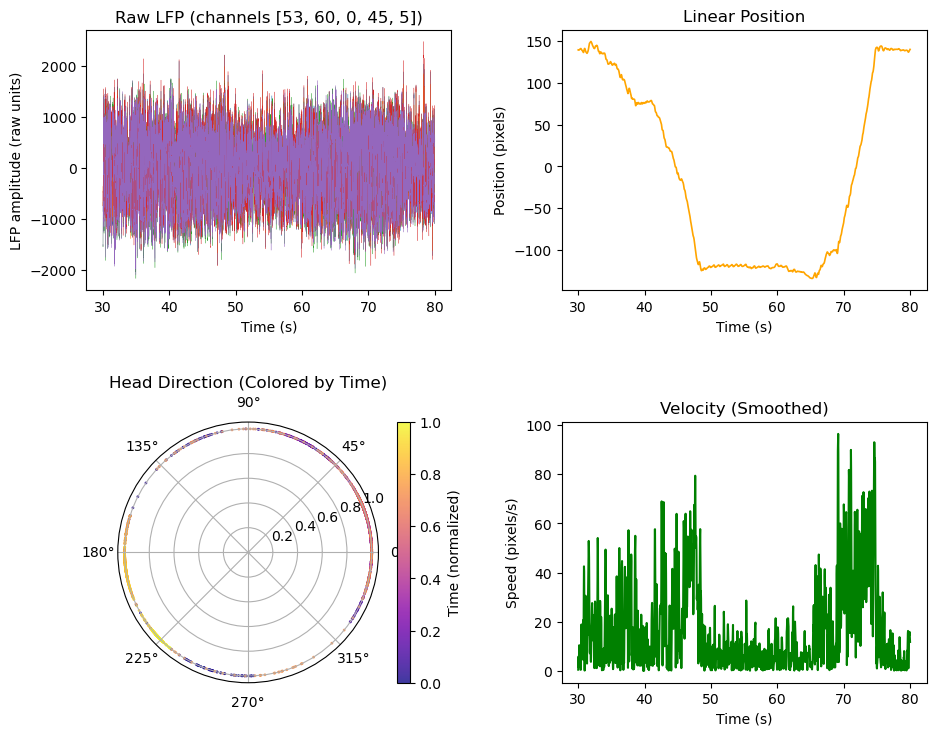

In [58]:
# Visualization bounds
upbound = 80
lowbound = 30

# Create masks
mask_lfp = (t_lfp <= upbound) & (t_lfp >= lowbound)
mask_pos = (t_pos <= upbound) & (t_pos >= lowbound)

# Randomly select 5 LFP channels
np.random.seed(42)
selected_channels = np.random.choice(65, size=5, replace=False)

# Create figure
fig, axs = plt.subplots(2, 2, figsize=(10, 8))

# --- LFP subplot ---
for i in range(5):
    axs[0, 0].plot(t_lfp[mask_lfp], data[selected_channels[i], mask_lfp], label=f'LFP ch {selected_channels[i]}', linewidth=0.2)
axs[0, 0].set_ylabel("LFP amplitude (raw units)", color='k')
axs[0, 0].set_xlabel("Time (s)")
axs[0, 0].tick_params(axis='y', labelcolor='k')
axs[0, 0].set_title(f"Raw LFP (channels {selected_channels.tolist()})")

# --- Position subplot ---
axs[0, 1].plot(t_pos[mask_pos], linear_pos[mask_pos], color='orange', linewidth=1.2)
axs[0, 1].set_title("Linear Position")
axs[0, 1].set_ylabel("Position (pixels)")
axs[0, 1].set_xlabel("Time (s)")

# --- Head direction (polar plot with time coloring) ---
ax_polar = plt.subplot(2, 2, 3, polar=True)
time_norm = (t_pos[mask_pos] - t_pos[mask_pos].min()) / (t_pos[mask_pos].max() - t_pos[mask_pos].min())
sc = ax_polar.scatter(head_dir_relative[mask_pos], np.ones_like(head_dir_relative[mask_pos]), c=time_norm, cmap='plasma', s=1, alpha=0.8)
ax_polar.set_title("Head Direction (Colored by Time)")
cbar = plt.colorbar(sc, ax=ax_polar, pad=0.05)
cbar.set_label("Time (normalized)")

# --- Velocity subplot ---
axs[1, 1].plot(t_pos[mask_pos], speed[mask_pos], color='green')
axs[1, 1].set_title("Velocity (Smoothed)")
axs[1, 1].set_ylabel("Speed (pixels/s)")
axs[1, 1].set_xlabel("Time (s)")

# Blank subplot
axs[1, 0].axis('off')

plt.tight_layout(pad=3.0)
plt.show()

/var/folders/tx/9bxcz_2j6m79n4dmyyw6s2zm0000gn/T/ipykernel_92355/3732498433.py:22: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  ax_polar = plt.subplot(2, 2, 3, polar=True)


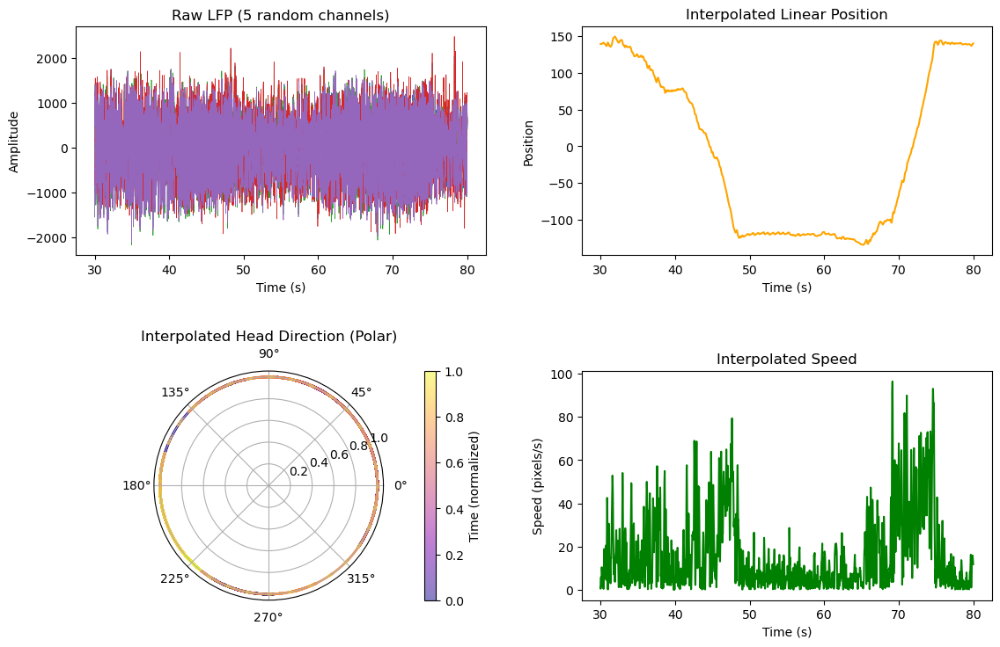

In [59]:
# Generate time vector for interpolated behavior (same as LFP)
t_interp = np.arange(interp_linear_pos.shape[0]) / sampling_rate
mask_interp = (t_interp >= 30) & (t_interp <= 80)

# Plot 2x2 grid: LFP, linear pos, head direction, speed (interpolated)
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# LFP channels (random 5)
for i in range(5):
    axs[0, 0].plot(t_interp[mask_interp], data[selected_channels[i], mask_interp], linewidth=0.5)
axs[0, 0].set_title("Raw LFP (5 random channels)")
axs[0, 0].set_ylabel("Amplitude")
axs[0, 0].set_xlabel("Time (s)")

# Interpolated linear position
axs[0, 1].plot(t_interp[mask_interp], interp_linear_pos[mask_interp], color='orange')
axs[0, 1].set_title("Interpolated Linear Position")
axs[0, 1].set_ylabel("Position")
axs[0, 1].set_xlabel("Time (s)")

# Polar plot of head direction
ax_polar = plt.subplot(2, 2, 3, polar=True)
time_norm = (t_interp[mask_interp] - t_interp[mask_interp].min()) / (t_interp[mask_interp].ptp())
sc = ax_polar.scatter(interp_head_dir[mask_interp], np.ones_like(interp_head_dir[mask_interp]),
                      c=time_norm, cmap='plasma', s=1, alpha=0.5)
ax_polar.set_title("Interpolated Head Direction (Polar)")
cbar = plt.colorbar(sc, ax=ax_polar, pad=0.1)
cbar.set_label("Time (normalized)")

# Interpolated speed
axs[1, 1].plot(t_interp[mask_interp], interp_speed[mask_interp], color='green')
axs[1, 1].set_title("Interpolated Speed")
axs[1, 1].set_ylabel("Speed (pixels/s)")
axs[1, 1].set_xlabel("Time (s)")

# Blank panel
axs[1, 0].axis('off')

plt.tight_layout(pad=3.0)
plt.show()


# LFP feature extraction

In [60]:

fs = 1250  # LFP sampling rate
window_ms = 200
window_size = int(fs * (window_ms / 1000))  # e.g., 200 ms → 250 samples
step_size = window_size/2  #

In [61]:
bands = {
    "delta": (1, 4),
    "theta": (6, 10),
    "beta": (12, 30),
    "low_gamma": (30, 55),
    "high_gamma": (65, 100)
}


In [62]:
def bandpower(data, fs, band, win_samples):
    low, high = band
    nyq = 0.5 * fs
    b, a = butter(4, [low/nyq, high/nyq], btype='band')
    filtered = filtfilt(b, a, data, axis=1)
    power = filtered**2
    return np.mean(power[:, :win_samples], axis=1)  # mean power per channel

In [63]:
n_channels, n_samples = data.shape
n_windows = (n_samples - window_size) // step_size

In [64]:
features_power = []
position_power = []
speed_power = []
head_dir_power = []

for i in range(int(n_windows)):
    start = int(i * step_size)
    end = int(start + window_size)

    window_data = data[:, start:end]
    feature_vector = []

    # --- LFP Band Power Features ---
    for band in bands.values():
        power = bandpower(window_data, fs, band, window_size)  # shape: (n_channels,)
        feature_vector.extend(power)

    features_power.append(feature_vector)

    # --- Behavioral Variables (matching window) ---
    pos_mean = np.nanmean(interp_linear_pos[start:end])
    speed_mean = np.nanmean(interp_speed[start:end])
    head_dir_mean = circmean(interp_head_dir[start:end], high=np.pi, low=-np.pi)

    position_power.append(pos_mean)
    speed_power.append(speed_mean)
    head_dir_power.append(head_dir_mean)

# --- Convert to arrays ---
features_power = np.array(features_power)
position_power = np.array(position_power)
speed_power = np.array(speed_power)
head_dir_power = np.array(head_dir_power)

In [65]:
X_power = np.array(features_power)       # shape: (n_windows, 325)
Y_position_power = np.array(position_power)     
Y_speeds_power = np.array(speed_power)  
Y_head_dirs_power = np.array(head_dir_power)  
X_power.shape, Y_position_power.shape, Y_speeds_power.shape, Y_head_dirs_power.shape

((10233, 325), (10233,), (10233,), (10233,))

In [66]:
bin_size = .1 # ms
n_bins = int(np.ceil(np.max(pos_time) / bin_size))
binned_spikes = []
for spikes in all_spikes:
    spike_bins = np.histogram(spikes, bins=np.arange(0, n_bins*bin_size, bin_size))[0]
    binned_spikes.append(spike_bins)
binned_spikes = np.array(binned_spikes)
# Check for NaN values in binned_spikes
print("Shape of binned_spikes:", binned_spikes.shape)
print("Number of NaN values:", np.isnan(binned_spikes).sum())
print("Percentage of NaN values:", (np.isnan(binned_spikes).sum() / binned_spikes.size) * 100, "%")


Shape of binned_spikes: (83, 10235)
Number of NaN values: 0
Percentage of NaN values: 0.0 %


# Experiment with Cebra

In [ ]:

from cebra import CEBRA
import cebra.integrations.plotly


In [68]:
max_iterations = 10000
output_dimension = 32

## cebra-time

In [69]:
cebra_model_time = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature=1,
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

### LFP

In [70]:
cebra_model_time.fit(X_power)
time_embedding = cebra_model_time.transform(X_power)

pos: -0.9326 neg:  6.3206 total:  5.3880 temperature:  1.0000: 100%|█| 10000/100


### Spikes

In [71]:
cebra_model_time.fit(binned_spikes.T)
spike_time_embedding = cebra_model_time.transform(binned_spikes.T)

pos: -0.9597 neg:  6.3387 total:  5.3790 temperature:  1.0000: 100%|█| 10000/100


In [72]:
fig = cebra.integrations.plotly.plot_embedding_interactive(time_embedding, embedding_labels=Y_position_power, title = "CEBRA-Time, color:position", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

In [73]:
spike_time_embedding.shape

(10235, 32)

In [74]:
fig = cebra.integrations.plotly.plot_embedding_interactive(spike_time_embedding[:10233,:], embedding_labels=Y_position_power, title = "CEBRA-Time, color:position", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

In [75]:
fig = cebra.integrations.plotly.plot_embedding_interactive(time_embedding, embedding_labels=Y_speeds_power, title = "CEBRA-Time, color:speeds", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

In [76]:
fig = cebra.integrations.plotly.plot_embedding_interactive(spike_time_embedding[:10233,:], embedding_labels=Y_speeds_power, title = "CEBRA-Time, color:position", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

In [77]:
fig = cebra.integrations.plotly.plot_embedding_interactive(time_embedding, embedding_labels=Y_head_dirs_power, title = "CEBRA-Time, color:head_dirs", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

In [78]:
fig = cebra.integrations.plotly.plot_embedding_interactive(spike_time_embedding[:10233,:], embedding_labels=Y_head_dirs_power, title = "CEBRA-Time, color:head_dirs", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

## cebra-linear position

In [79]:
cebra_model_position = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature=1,
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [80]:
cebra_model_position.fit(X_power, Y_position_power)
position_embedding = cebra_model_position.transform(X_power)


cebra_model_position.fit(binned_spikes[:, :10233].T, Y_position_power)
spike_position_embedding = cebra_model_position.transform(binned_spikes[:, :10233].T)

pos: -0.9310 neg:  6.5148 total:  5.5838 temperature:  1.0000: 100%|█| 10000/100
pos: -0.9157 neg:  6.4671 total:  5.5513 temperature:  1.0000: 100%|█| 10000/100


In [91]:
spike_position_embedding.shape

(10233, 32)

In [93]:
position_embedding.shape

(10233, 32)

In [92]:
fig = cebra.integrations.plotly.plot_embedding_interactive(position_embedding, embedding_labels=Y_position_power, title = "CEBRA-Position", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

In [82]:
fig = cebra.integrations.plotly.plot_embedding_interactive(spike_position_embedding, embedding_labels=Y_position_power, title = "CEBRA-Position", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

## cebra-speed

In [83]:
cebra_model_speed = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature=1,
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [84]:
cebra_model_speed.fit(X_power, Y_speeds_power)
speed_embedding = cebra_model_speed.transform(X_power)


cebra_model_speed.fit(binned_spikes[:, :10233].T, Y_speeds_power)
spike_speed_embedding = cebra_model_speed.transform(binned_spikes[:, :10233].T)

pos: -0.4895 neg:  6.4495 total:  5.9600 temperature:  1.0000: 100%|█| 10000/100
pos: -0.5629 neg:  6.4659 total:  5.9031 temperature:  1.0000: 100%|█| 10000/100


In [85]:
fig = cebra.integrations.plotly.plot_embedding_interactive(speed_embedding, embedding_labels=Y_speeds_power, title = "CEBRA-Speed", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

In [86]:
fig = cebra.integrations.plotly.plot_embedding_interactive(spike_speed_embedding, embedding_labels=Y_speeds_power, title = "CEBRA-Speed", cmap = "inferno")
fig.show()

## mixture of experts 
## joint latent space - starfish 


<Figure size 500x500 with 0 Axes>

## cebra-head_dir

In [87]:
cebra_model_head_dir = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature=1,
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [88]:
cebra_model_head_dir.fit(X_power, Y_head_dirs_power)
head_dir_embedding = cebra_model_head_dir.transform(X_power)

cebra_model_head_dir.fit(binned_spikes[:, :10233].T, Y_speeds_power)
spike_head_dir_embedding = cebra_model_head_dir.transform(binned_spikes[:, :10233].T)

pos: -0.5955 neg:  6.4838 total:  5.8883 temperature:  1.0000: 100%|█| 10000/100
pos: -0.5125 neg:  6.4646 total:  5.9521 temperature:  1.0000: 100%|█| 10000/100


In [89]:
fig = cebra.integrations.plotly.plot_embedding_interactive(head_dir_embedding, embedding_labels=Y_head_dirs_power, title = "CEBRA-head_dir", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

In [90]:
fig = cebra.integrations.plotly.plot_embedding_interactive(spike_head_dir_embedding, embedding_labels=Y_head_dirs_power, title = "CEBRA-head_dir", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>